In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/manutencao_preditiva.csv")
print(df.shape)
print(df.dtypes)

(10000, 14)
udi                          int64
id_produto                     str
tipo                           str
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object


In [2]:
df.describe()

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [3]:
df.isna().sum()

udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf                    0
dtype: int64

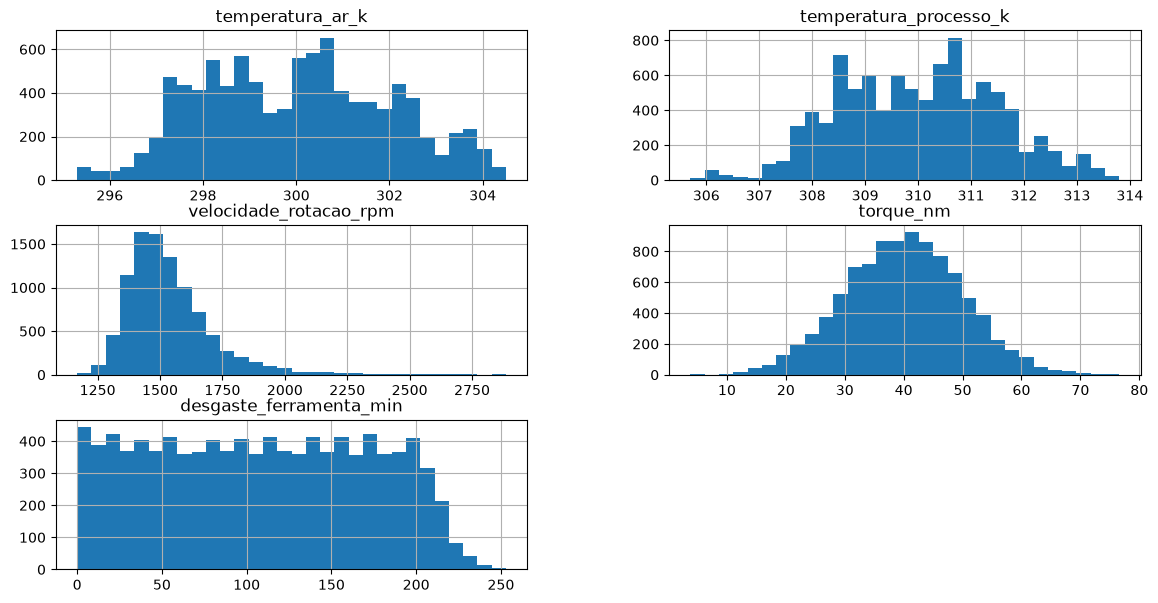

In [4]:
colunas = ["temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm",
           "torque_nm", "desgaste_ferramenta_min"]

df[colunas].hist(bins=30, figsize=(14, 7))
plt.show()

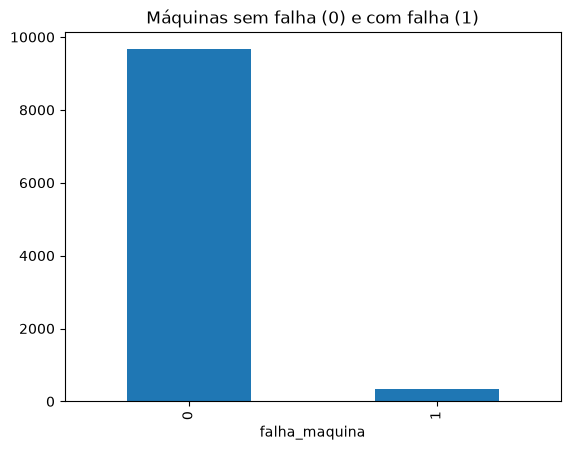

In [5]:
df["falha_maquina"].value_counts().plot(kind="bar")
plt.title("Máquinas sem falha (0) e com falha (1)")
plt.show()

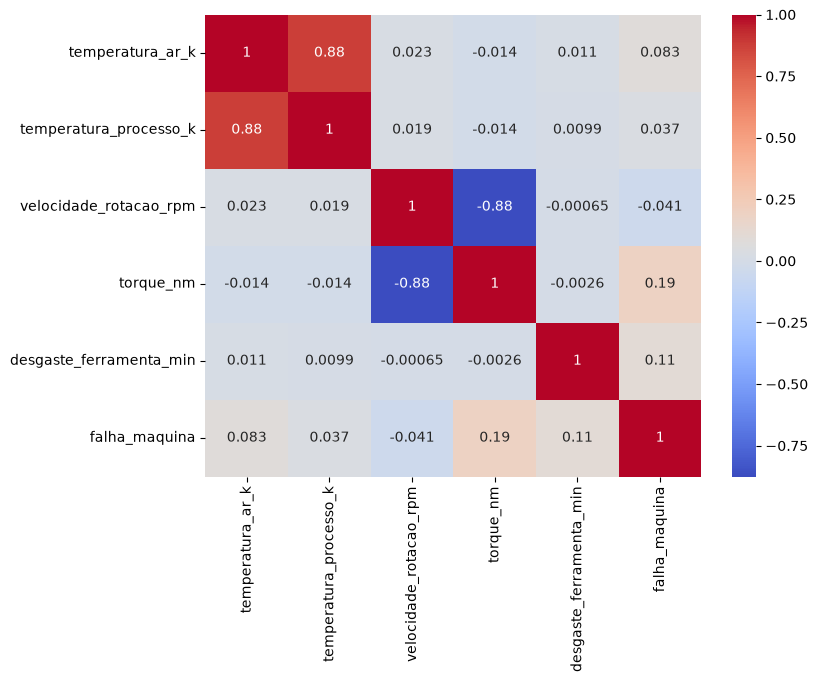

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[colunas + ["falha_maquina"]].corr(), annot=True, cmap="coolwarm")
plt.show()

### Análise da Fase 1
A base tem 10.000 linhas e 14 colunas. As colunas temperatura_ar_k, temperatura_processo_k, velocidade_rotacao_rpm e torque_nm têm 500 valores
ausentes cada (5%). Só 3,4% das máquinas falharam (339 máquinas), então os dados são desbalanceados e vou usar SMOTE no treino. A variável velocidade_rotacao_rpm é assimétrica (média maior que a mediana), então vou preencher os ausentes com a MEDIANA . A variável com maior correlação
com a falha é torque_nm (0,19), mas é fraca. Por isso vou criar a nova coluna potencia e testar os modelos que combinam com as variáveis.Como as escalas das variáveis são muito diferentes, vou usar StandardScaler no KNN.

In [7]:
print("Linhas antes:", len(df))
df = df.drop_duplicates()
print("Linhas depois:", len(df))

Linhas antes: 10000
Linhas depois: 10000


In [8]:
print(df[colunas].skew())

temperatura_ar_k           0.114931
temperatura_processo_k     0.015643
velocidade_rotacao_rpm     1.994640
torque_nm                 -0.007881
desgaste_ferramenta_min    0.027292
dtype: float64


In [9]:
sensores = ["temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm", "torque_nm"]

for c in sensores:
    df[c] = df[c].fillna(df[c].median())

print(df.isna().sum())

udi                        0
id_produto                 0
tipo                       0
temperatura_ar_k           0
temperatura_processo_k     0
velocidade_rotacao_rpm     0
torque_nm                  0
desgaste_ferramenta_min    0
falha_maquina              0
falha_twf                  0
falha_hdf                  0
falha_pwf                  0
falha_osf                  0
falha_rnf                  0
dtype: int64


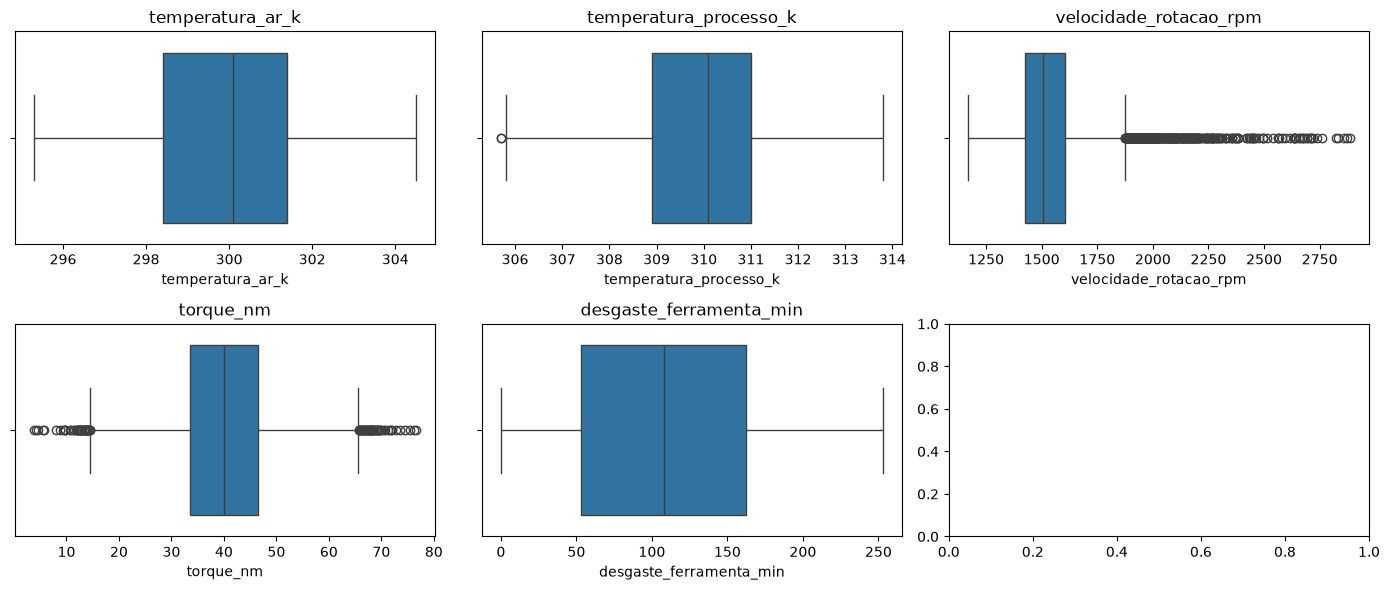

In [10]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 6))
eixos = eixos.ravel()
for eixo, c in zip(eixos, colunas):
    sns.boxplot(x=df[c], ax=eixo)
    eixo.set_title(c)
plt.tight_layout()
plt.show()

In [11]:
for c in colunas:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    limite_baixo = q1 - 1.5 * (q3 - q1)
    limite_alto = q3 + 1.5 * (q3 - q1)
    qtd = ((df[c] < limite_baixo) | (df[c] > limite_alto)).sum()
    print(c, ":", qtd, "outliers")

temperatura_ar_k : 0 outliers
temperatura_processo_k : 2 outliers
velocidade_rotacao_rpm : 465 outliers
torque_nm : 102 outliers
desgaste_ferramenta_min : 0 outliers


### Análise da Fase 2
Duplicadas: 0 linhas foram removidas, não encontrei duplicadas, porque o udi é único em cada linha.
Ausentes: as 4 colunas de sensores tinham 500 valores ausentes cada. Preenchi com a
mediana porque a velocidade_rotacao_rpm tem assimetria de 1,99, e a média seria puxada
por valores extremos.
Outliers: o boxplot mostrou outliers principalmente em velocidade_rotacao_rpm (465) e
torque_nm (102). Decidi manter os outliers porque podem ser leituras reais de máquinas sob esforço, e removê-los poderia eliminar linhas de falha, que são só 339.

In [12]:
df["potencia"] = df["velocidade_rotacao_rpm"] * df["torque_nm"]
print(df["potencia"].isna().sum())
df["potencia"].describe()

0


count    10000.000000
mean     59970.673120
std       9951.344325
min      10966.800000
25%      53497.050000
50%      60310.400000
75%      66412.975000
max      99980.400000
Name: potencia, dtype: float64

In [13]:
df["tipo"] = df["tipo"].map({"L": 0, "M": 1, "H": 2})

X = df.drop(columns=["falha_maquina", "udi", "id_produto",
                     "falha_twf", "falha_hdf", "falha_pwf", "falha_osf", "falha_rnf"])
y = df["falha_maquina"]
print(X.columns)

Index(['tipo', 'temperatura_ar_k', 'temperatura_processo_k',
       'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min',
       'potencia'],
      dtype='str')


In [14]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_treino.shape, X_teste.shape)
print(y_treino.value_counts())
print(y_teste.value_counts())

(8000, 7) (2000, 7)
falha_maquina
0    7729
1     271
Name: count, dtype: int64
falha_maquina
0    1932
1      68
Name: count, dtype: int64


In [15]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_treino_bal, y_treino_bal = smote.fit_resample(X_treino, y_treino)
X_treino_bal["tipo"] = X_treino_bal["tipo"].round()

print(y_treino_bal.value_counts())
print(y_teste.value_counts())

falha_maquina
0    7729
1    7729
Name: count, dtype: int64
falha_maquina
0    1932
1      68
Name: count, dtype: int64


In [16]:
from sklearn.preprocessing import StandardScaler

continuas = ["temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm",
             "torque_nm", "desgaste_ferramenta_min", "potencia"]

scaler = StandardScaler()
X_treino_knn = X_treino_bal.copy()
X_teste_knn = X_teste.copy()

X_treino_knn[continuas] = scaler.fit_transform(X_treino_bal[continuas])
X_teste_knn[continuas] = scaler.transform(X_teste[continuas])

In [17]:
X_treino_arv = X_treino_bal
X_teste_arv = X_teste

A árvore não precisa de escala porque só importa a ordem dos valores. Já o KNN ele procura as máquinas mais parecidas, medindo a distância entre os pontos, somando as diferenças de cada coluna
então uma coluna com números grandes (como o rpm) se destaca das as outras, por isso usei o StandardScaler.

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

resultados_knn = []
for k in [3, 5, 7, 9, 11]:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_treino_knn, y_treino_bal)
    acc_treino = accuracy_score(y_treino_bal, modelo.predict(X_treino_knn))
    acc_teste = accuracy_score(y_teste, modelo.predict(X_teste_knn))
    resultados_knn.append([k, acc_treino, acc_teste])

tabela_knn = pd.DataFrame(resultados_knn, columns=["K", "acc_treino", "acc_teste"])
tabela_knn

,K,acc_treino,acc_teste
0,3,0.965002,0.9055
1,5,0.953357,0.8985
2,7,0.946241,0.8890
3,9,0.940160,0.8850
4,11,0.936408,0.8820


In [19]:
from sklearn.tree import DecisionTreeClassifier

resultados_arv = []
for d in [3, 5, 8, None]:
    modelo = DecisionTreeClassifier(max_depth=d, random_state=42)
    modelo.fit(X_treino_arv, y_treino_bal)
    acc_treino = accuracy_score(y_treino_bal, modelo.predict(X_treino_arv))
    acc_teste = accuracy_score(y_teste, modelo.predict(X_teste_arv))
    resultados_arv.append([str(d), acc_treino, acc_teste])

tabela_arv = pd.DataFrame(resultados_arv, columns=["max_depth", "acc_treino", "acc_teste"])
tabela_arv

,max_depth,acc_treino,acc_teste
0,3,0.851210,0.8595
1,5,0.899275,0.8995
2,8,0.918359,0.9020
3,None,0.992560,0.9305


### Overfitting
No KNN, o maior overfitting ficou com K = 3, onde o treino deu 96,5% e o teste 90,55%.
Na árvore, com max_depth=None o treino foi 99,26% e o teste 93,05%, ou seja, a árvore decorou o treino.
A configuração mais estável foi max_depth = 5, porque treino e teste ficaram quase iguais (89,9% e 89,95%).

In [20]:
modelo_knn = KNeighborsClassifier(n_neighbors=3)
modelo_knn.fit(X_treino_knn, y_treino_bal)
acc_knn = accuracy_score(y_teste, modelo_knn.predict(X_teste_knn))

modelo_arv = DecisionTreeClassifier(max_depth=None, random_state=42)
modelo_arv.fit(X_treino_arv, y_treino_bal)
acc_arv = accuracy_score(y_teste, modelo_arv.predict(X_teste_arv))

print("KNN (K=3):", acc_knn)
print("Árvore (max_depth=None):", acc_arv)

KNN (K=3): 0.9055
Árvore (max_depth=None): 0.9305


In [21]:
from sklearn.metrics import recall_score

print("Sempre prever 'normal':", y_teste.value_counts(normalize=True).max())
print("Recall KNN:", recall_score(y_teste, modelo_knn.predict(X_teste_knn)))
print("Recall árvore:", recall_score(y_teste, modelo_arv.predict(X_teste_arv)))

Sempre prever 'normal': 0.966
Recall KNN: 0.6470588235294118
Recall árvore: 0.6911764705882353


### Conclusão
A árvore de decisão teve acurácia de 93,05% no teste, contra 90,55% do KNN, então o modelo
indicado é a árvore de decisão. Porém, a acurácia sozinha engana. Só 3,4% das máquinas falham, então um modelo que sempre previsse "normal" acertaria 96,6%, um valor maior que o dos dois modelos que treinei. O recall da árvore foi 69% e o do KNN 65%. Ou seja, ainda cerca de 1/3 das quebras reais não são detectadas. Como melhoria, eu usaria recall e F1 para escolher o modelo, testaria mais modelos e faria validação cruzada.